In [1]:
from pathlib import Path
import random
import torch
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED)
torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
out = Path("lab_outputs")
out.mkdir(exist_ok=True)
print("Device:", device)

Device: cuda


In [2]:
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from torchvision.utils import make_grid

transform = transforms.Compose([
    transforms.ToTensor(), transforms.Normalize((0.5,), (0.5,))
])
data = datasets.FashionMNIST("data", train=True, download=True,
                             transform=transform)
loader = DataLoader(data, batch_size=128, shuffle=True)
print("Train images:", len(data))

100%|██████████| 26.4M/26.4M [00:00<00:00, 114MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 3.90MB/s]
100%|██████████| 4.42M/4.42M [00:00<00:00, 60.1MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 3.60MB/s]


Train images: 60000


In [3]:
latent_dim = 64
G = nn.Sequential(nn.Linear(latent_dim, 256), nn.LeakyReLU(0.2),
                  nn.Linear(256, 512), nn.LeakyReLU(0.2),
                  nn.Linear(512, 784), nn.Tanh()).to(device)
D = nn.Sequential(nn.Flatten(), nn.Linear(784, 512), nn.LeakyReLU(0.2),
                  nn.Linear(512, 256), nn.LeakyReLU(0.2),
                  nn.Linear(256, 1)).to(device)
loss_fn = nn.BCEWithLogitsLoss()
opt_g = torch.optim.Adam(G.parameters(), lr=0.0002, betas=(0.5, 0.999))
opt_d = torch.optim.Adam(D.parameters(), lr=0.0002, betas=(0.5, 0.999))
fixed_z = torch.randn(25, latent_dim, device=device)

with torch.no_grad():
    z = torch.randn(8, latent_dim, device=device)
    fake = G(z)
    print("Noise batch:", tuple(z.shape))
    print("Generator output:", tuple(fake.shape), "| min/max:", round(fake.min().item(), 2), round(fake.max().item(), 2))
    print("Discriminator output:", tuple(D(fake).shape))

Noise batch: (8, 64)
Generator output: (8, 784) | min/max: -0.39 0.35
Discriminator output: (8, 1)


In [4]:
def generate_grid(epoch):
    with torch.no_grad():
        images = G(fixed_z).cpu().reshape(-1, 1, 28, 28)
        grid = make_grid((images + 1) / 2, nrow=5)
    plt.figure(figsize=(5, 5))
    plt.imshow(grid.permute(1, 2, 0))
    plt.title(f"Epoch {epoch}")
    plt.axis("off")
    plt.savefig(out / f"gan_epoch_{epoch:02d}.png", bbox_inches="tight")
    plt.show()

def train_batch(real):
    n = real.size(0)
    fake = G(torch.randn(n, latent_dim, device=device))
    real_logits = D(real)
    fake_logits = D(fake.detach())
    d_loss = (loss_fn(real_logits, torch.ones_like(real_logits))
              + loss_fn(fake_logits, torch.zeros_like(fake_logits))) / 2
    opt_d.zero_grad()
    d_loss.backward()
    opt_d.step()

    D.requires_grad_(False)
    opt_g.zero_grad()
    logits = D(fake)
    g_loss = loss_fn(logits, torch.ones_like(logits))
    g_loss.backward()
    opt_g.step()
    D.requires_grad_(True)
    return d_loss.item(), g_loss.item()

01 D=0.350 G=1.823


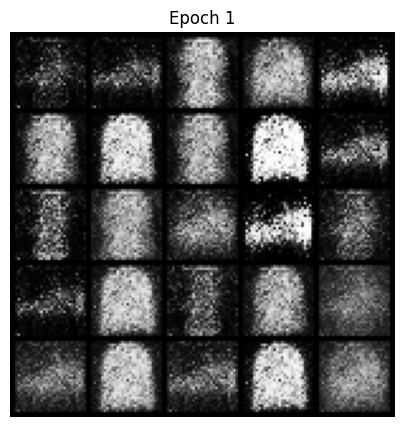

02 D=0.322 G=2.789
03 D=0.361 G=2.392
04 D=0.397 G=2.056
05 D=0.406 G=2.082


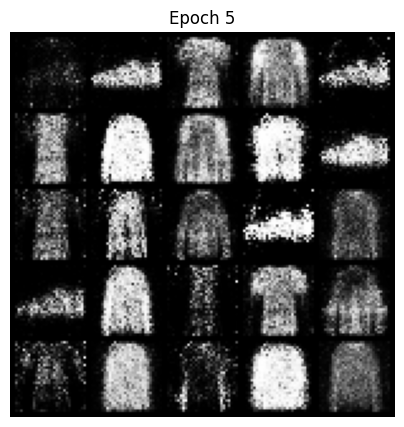

06 D=0.423 G=1.922
07 D=0.425 G=1.900
08 D=0.423 G=1.939
09 D=0.446 G=1.842
10 D=0.461 G=1.743


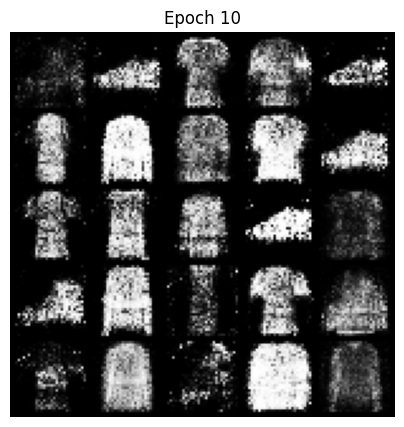

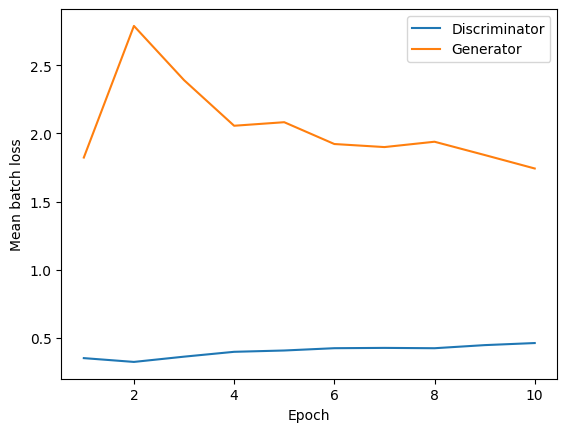

In [5]:
history = []
for epoch in range(1, 11):
    losses = [train_batch(real.to(device)) for real, _ in loader]
    avg_d, avg_g = [sum(values) / len(losses) for values in zip(*losses)]
    history.append((avg_d, avg_g))
    print(f"{epoch:02d} D={avg_d:.3f} G={avg_g:.3f}")
    if epoch in (1, 5, 10):
        generate_grid(epoch)

plt.plot(range(1, 11), [d for d, g in history], label="Discriminator")
plt.plot(range(1, 11), [g for d, g in history], label="Generator")
plt.xlabel("Epoch")
plt.ylabel("Mean batch loss")
plt.legend()
plt.savefig(out / "gan_losses.png", bbox_inches="tight")
plt.show()
torch.save(G.state_dict(), out / "fashion_generator.pt")

In [6]:
print(f"{'Epoch':<8}{'D loss':<10}{'G loss':<10}")
for e in (1, 5, 10):
    d, g = history[e - 1]
    print(f"{e:<8}{d:<10.3f}{g:<10.3f}")


Epoch   D loss    G loss    
1       0.350     1.823     
5       0.406     2.082     
10      0.461     1.743     
